# AR(p) sliding point clouds and Mahalanobis recurrence graphs

This notebook simulates a stationary AR($p$) time series, embeds it into forward delay vectors, forms a moving sequence of local point clouds

$$
Y_t^{(m)} = (X_t, X_{t+1}, \ldots, X_{t+m-1}),
\qquad
P_k = \{Y_k^{(m)}, \ldots, Y_{k+w-1}^{(m)}\},
$$

and builds one recurrence graph $G_k$ from every local cloud $P_k$.

For each cloud, distances are computed with the cloud-specific covariance matrix:

$$
d_k(y_i,y_j)
= \sqrt{(y_i-y_j)^\top (\widehat\Sigma_k + \lambda I)^{-1}(y_i-y_j)}.
$$

An edge is inserted when the Mahalanobis distance is below a chosen recurrence threshold. The default threshold is a distance quantile, so each graph has a comparable recurrence scale even when local covariance changes over time.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.linalg import pinvh

PROJECT_ROOT = Path.cwd().resolve()
HELPER_CANDIDATES = [
    PROJECT_ROOT,
    PROJECT_ROOT / "Code",
    PROJECT_ROOT / "Code" / "Code_AR_processes",
    PROJECT_ROOT / "Code_AR_processes",
    PROJECT_ROOT.parent,
    PROJECT_ROOT.parent / "Code",
    PROJECT_ROOT.parent / "Code_AR_processes",
]
for directory in HELPER_CANDIDATES:
    if (directory / "00_FUNCTIONS.py").exists() and str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
        break

from importlib import import_module
helpers = import_module("00_FUNCTIONS")

automatic_ar_coefficients = helpers.automatic_ar_coefficients
companion_radius = helpers.companion_radius
simulate_ar = helpers.simulate_ar
aligned_windows = helpers.aligned_windows

plt.rcParams.update({
    "figure.figsize": (8, 4.8),
    "axes.grid": True,
    "grid.alpha": 0.25,
})

## 1. Parameters

Use `p` for the AR order and `embedding_dimension` for the delay-vector dimension $m$. A natural first choice is `embedding_dimension = p + 1`, but the notebook lets you change it independently.

The graph threshold can be controlled in two ways:

- `threshold_mode = "quantile"`: use the selected quantile of all pairwise Mahalanobis distances in each $P_k$.
- `threshold_mode = "fixed"`: use the same numeric `fixed_epsilon` for all clouds.

In [2]:
# AR model and sample path
p = 2
n_observations = 900
burn_in = 500
innovation_sd = 1.0
seed = 20260709

# Delay embedding and local clouds P_k
embedding_dimension = p + 1
max_embedding_dimension = 8
cloud_size = 90
cloud_step = 20

# Recurrence graph settings
threshold_mode = "quantile"  # choose "quantile" or "fixed"
recurrence_quantile = 0.12
fixed_epsilon = 2.5
covariance_ridge = 1e-8

# Plotting controls
selected_cloud_indices = [0, 8, 16]
max_edges_to_draw = 500

## 2. Helper functions

## 3. Generate one AR(p) path

The coefficients are generated from partial autocorrelations, which guarantees stationarity as long as all partial autocorrelations are inside $(-1,1)$.

In [4]:
rng = np.random.default_rng(seed)
phi = automatic_ar_coefficients(p)
x = simulate_ar(
    phi=phi,
    n=n_observations,
    burn_in=burn_in,
    innovation_sd=innovation_sd,
    rng=rng,
)

print(f"AR({p}) coefficients: {np.round(phi, 6)}")
print(f"Companion spectral radius: {companion_radius(phi):.4f}")
print(f"Generated observations: {len(x)}")

AR(2) coefficients: [ 1.03125 -0.375  ]
Companion spectral radius: 0.6124
Generated observations: 900


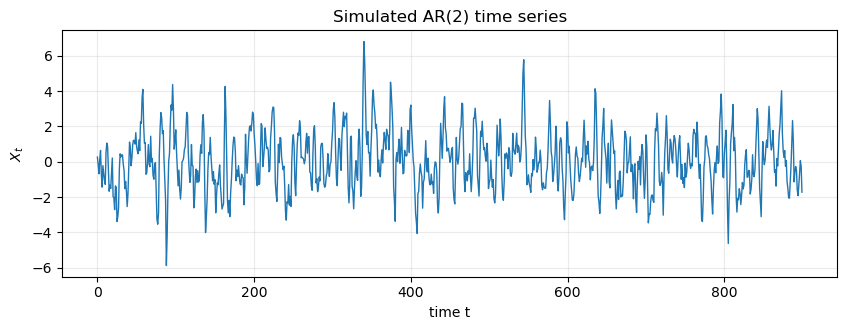

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(x, color="tab:blue", linewidth=1.0)
ax.set(
    title=f"Simulated AR({p}) time series",
    xlabel="time t",
    ylabel=r"$X_t$",
)
plt.show()

## 4. Delay vectors and local clouds $P_k$

In [6]:
embedded = aligned_windows(x, embedding_dimension).copy()
point_clouds, cloud_starts = make_local_point_clouds(
    embedded,
    cloud_size=cloud_size,
    step=cloud_step,
)

print(f"Embedding dimension m = {embedding_dimension}")
print(f"Total delay vectors Y_t: {len(embedded)}")
print(f"Number of local clouds P_k: {len(point_clouds)}")
print(f"Each P_k contains {cloud_size} delay vectors")

Embedding dimension m = 3
Total delay vectors Y_t: 898
Number of local clouds P_k: 41
Each P_k contains 90 delay vectors


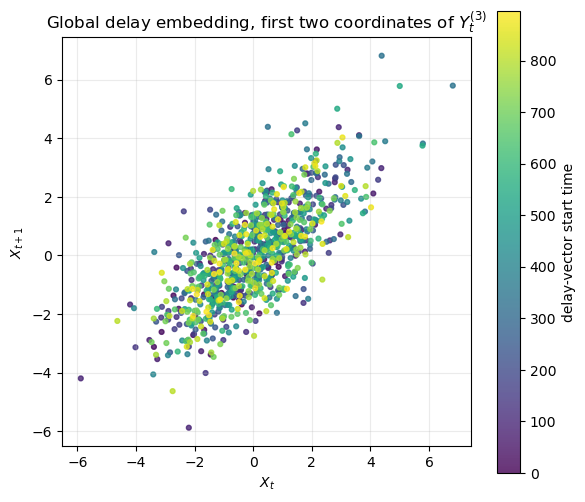

In [7]:
fig, ax = plt.subplots(figsize=(6.6, 6.0))
scatter = ax.scatter(
    embedded[:, 0],
    embedded[:, 1],
    c=np.arange(len(embedded)),
    cmap="viridis",
    s=12,
    alpha=0.8,
)
ax.set(
    title=rf"Global delay embedding, first two coordinates of $Y_t^{{({embedding_dimension})}}$",
    xlabel=r"$X_t$",
    ylabel=r"$X_{t+1}$",
)
ax.set_aspect("equal", adjustable="box")
fig.colorbar(scatter, ax=ax, label="delay-vector start time")
plt.show()

## 5. Build recurrence graphs $G_k$

For every local cloud $P_k$, we estimate its covariance matrix, compute all Mahalanobis distances, choose the recurrence threshold, and insert an edge for every pair below that threshold.

In [8]:
recurrence_results = [
    build_recurrence_graph(
        cloud,
        threshold_mode=threshold_mode,
        quantile=recurrence_quantile,
        epsilon=fixed_epsilon,
        ridge=covariance_ridge,
    )
    for cloud in point_clouds
]

graph_summaries = []
for cloud_index, (start, result) in enumerate(zip(cloud_starts, recurrence_results)):
    summary = summarize_graph(result["graph"])
    summary.update({
        "cloud_index": cloud_index,
        "start_t": int(start),
        "end_t": int(start + cloud_size - 1),
        "threshold": result["threshold"],
        "cov_condition": np.linalg.cond(result["covariance"]),
    })
    graph_summaries.append(summary)

summary_df = pd.DataFrame(graph_summaries)[[
    "cloud_index", "start_t", "end_t", "threshold", "vertices", "edges",
    "density", "components", "largest_component", "cov_condition",
]]
summary_df.head(10)

,cloud_index,start_t,end_t,threshold,vertices,edges,density,components,largest_component,cov_condition
0,0,0,89,1.098944,90,481,0.1201,7,83,21.020888
1,1,20,109,1.123662,90,481,0.1201,7,84,25.673266
2,2,40,129,1.106898,90,481,0.1201,9,82,21.160743
3,3,60,149,1.132388,90,481,0.1201,12,79,20.043282
4,4,80,169,1.143004,90,481,0.1201,11,79,22.790927
5,5,100,189,1.138213,90,481,0.1201,8,83,14.948068
6,6,120,209,1.150586,90,481,0.1201,8,82,17.943476
7,7,140,229,1.159964,90,481,0.1201,8,83,19.757000
8,8,160,249,1.155872,90,481,0.1201,7,83,19.208453
9,9,180,269,1.170468,90,481,0.1201,3,88,17.875706


In [9]:
summary_df.describe().T

,count,mean,std,min,25%,50%,75%,max
cloud_index,41.0,20.000000,1.197915e+01,0.000000,10.000000,20.000000,30.000000,40.000000
start_t,41.0,400.000000,2.395830e+02,0.000000,200.000000,400.000000,600.000000,800.000000
end_t,41.0,489.000000,2.395830e+02,89.000000,289.000000,489.000000,689.000000,889.000000
threshold,41.0,1.158621,4.641220e-02,1.069727,1.128504,1.155872,1.184683,1.262101
vertices,41.0,90.000000,0.000000e+00,90.000000,90.000000,90.000000,90.000000,90.000000
edges,41.0,481.000000,0.000000e+00,481.000000,481.000000,481.000000,481.000000,481.000000
density,41.0,0.120100,1.405019e-17,0.120100,0.120100,0.120100,0.120100,0.120100
components,41.0,6.048780,3.185524e+00,1.000000,4.000000,7.000000,8.000000,12.000000
largest_component,41.0,84.756098,3.307420e+00,79.000000,83.000000,84.000000,87.000000,90.000000
cov_condition,41.0,19.289980,3.474722e+00,11.579392,17.421744,19.353525,21.520262,25.862212


## 6. Inspect selected recurrence graphs

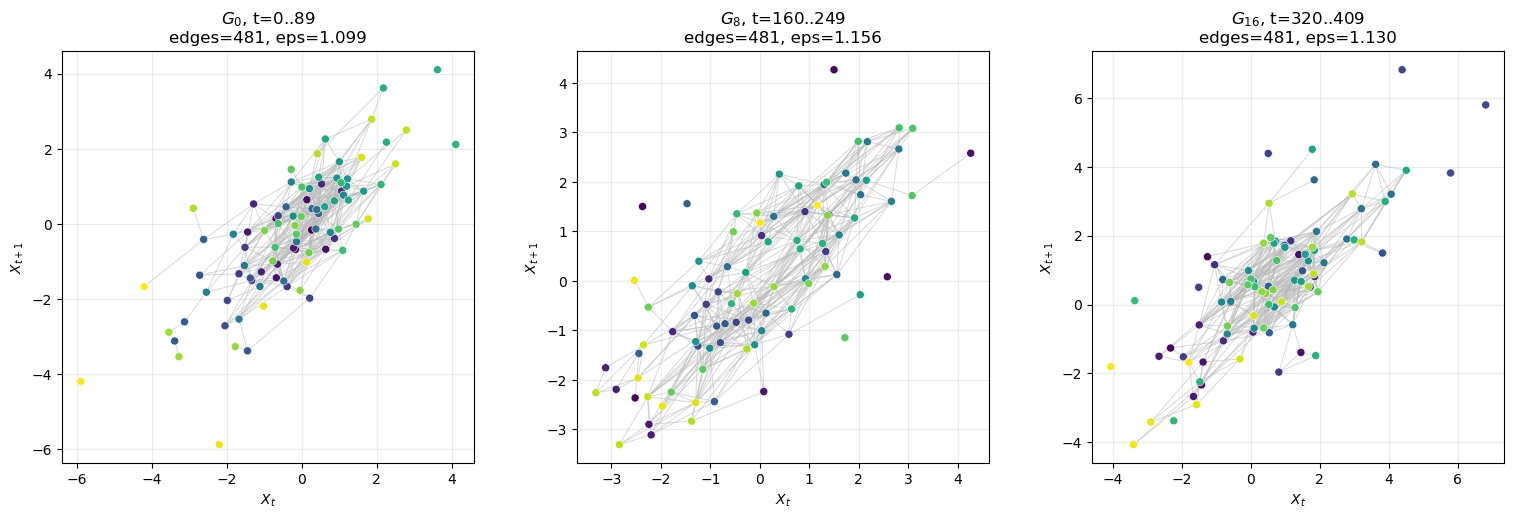

In [10]:
valid_indices = [i for i in selected_cloud_indices if 0 <= i < len(point_clouds)]
if not valid_indices:
    valid_indices = [0]

fig, axes = plt.subplots(1, len(valid_indices), figsize=(5.2 * len(valid_indices), 5.0), squeeze=False)
for ax, cloud_index in zip(axes.ravel(), valid_indices):
    cloud = point_clouds[cloud_index]
    result = recurrence_results[cloud_index]
    graph = result["graph"]
    title = (
        rf"$G_{{{cloud_index}}}$, "
        f"t={cloud_starts[cloud_index]}..{cloud_starts[cloud_index] + cloud_size - 1}\n"
        f"edges={graph.number_of_edges()}, eps={result['threshold']:.3f}"
    )
    plot_cloud_graph(cloud, graph, title=title, max_edges=max_edges_to_draw, ax=ax)
plt.tight_layout()
plt.show()

## 7. Graph statistics over time

## 8. Distance and adjacency matrices for one $G_k$

## 9. Network NMI scale selection over embedding dimensions

The previous sections build a time stream of local recurrence graphs. That is useful for dynamics, but it does **not** estimate the AR order.

For order selection, we now let the scale index mean the delay-window dimension. For each candidate dimension

$$
k=1,
\ldots,
k_{\max},
$$

we build

$$
P_k=\{(X_t,\ldots,X_{t+k-1}):t=0,\ldots,n-k_{\max}\}
$$

using the same vertex/time set for every $k$. From each $P_k$ we build a Mahalanobis recurrence graph $G_k$. The graph-similarity matrix is filled using the normalized network mutual information from Felippe, Battiston, and Kirkley: for node-aligned graphs, it compares the upper-triangular adjacency entries as binary edge labels.

The literal scale-selection principle is then applied as follows:

$$
k^* = \arg\max_k v_k,
$$

where $v$ is the Perron/leading eigenvector of the NMI similarity matrix. The notebook also reports an adjacent-drop diagnostic, but that diagnostic is not called $k^*$ because it is not the Perron-vector rule.

## 9b. Embedded birth-death chain on adjacent NMI distances

The NMI diagonal is identically one, so it cannot be used as a monotone profile. Instead we form a monotone cumulative graph-change profile from adjacent NMI distances:

$$
c_1=0,
\qquad
c_{k+1}=c_k+\left(1-\operatorname{NMI}(G_k,G_{k+1})\right).
$$

The increments are therefore

$$
d_k=c_{k+1}-c_k=1-\operatorname{NMI}(G_k,G_{k+1}).
$$

From these increments we build the embedded birth-death jump chain. Its stationary distribution is proportional to the exit rates

$$
r_1=d_1^{-1},\qquad
r_k=d_{k-1}^{-1}+d_k^{-1},\qquad
r_N=d_{N-1}^{-1}.
$$

The global minimum is reported, and so is the interior minimum. The interior minimum is often the more meaningful order-selection diagnostic because endpoints have only one neighboring increment.

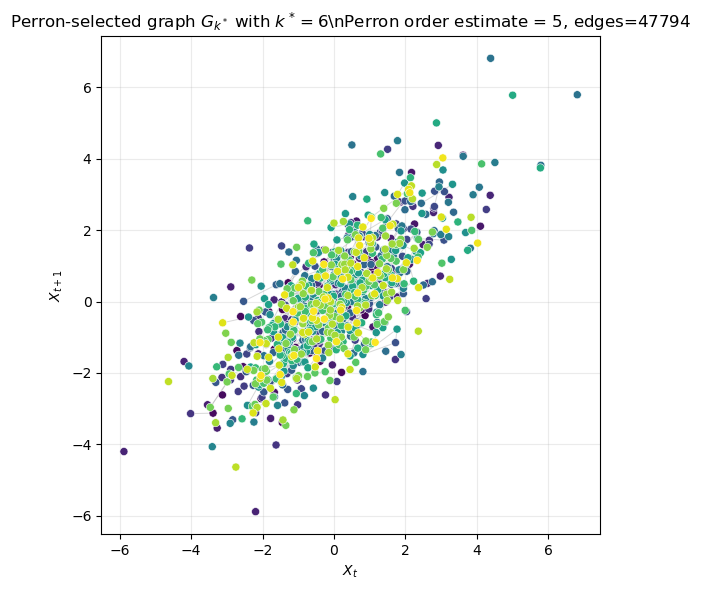

In [17]:
selected_scale_result = scale_results[k_star]
selected_scale_graph = selected_scale_result["graph"]
selected_scale_cloud = scale_clouds[k_star]

fig, ax = plt.subplots(figsize=(6.2, 6.0))
if selected_scale_cloud.shape[1] >= 2:
    plot_cloud_graph(
        selected_scale_cloud,
        selected_scale_graph,
        title=(
            rf"Perron-selected graph $G_{{k^*}}$ with $k^*={k_star}$\n"
            f"Perron order estimate = {perron_order_estimate}, edges={selected_scale_graph.number_of_edges()}"
        ),
        max_edges=max_edges_to_draw,
        ax=ax,
    )
else:
    values = selected_scale_cloud[:, 0]
    for i, j, data in selected_scale_graph.edges(data=True):
        ax.plot([i, j], [values[i], values[j]], color="0.72", linewidth=0.5, alpha=0.35)
    ax.scatter(np.arange(len(values)), values, s=14, color="tab:blue", zorder=2)
    ax.set(
        title=(
            rf"Perron-selected graph $G_{{k^*}}$ with $k^*={k_star}$\n"
            f"Perron order estimate = {perron_order_estimate}, edges={selected_scale_graph.number_of_edges()}"
        ),
        xlabel="vertex/time index",
        ylabel=r"$X_t$",
    )
plt.tight_layout()
plt.show()

## 9c. Monte Carlo check for AR(1)

This experiment repeats the dimension-indexed graph construction for many independent AR(1) paths. The target embedding dimension is $k=p+1=2$.

For speed, this cell compares recurrence graphs through their upper-triangular edge vectors directly. This gives the same standard network NMI as the NetworkX graph version, but avoids repeated graph-to-matrix conversions.

## 9d. Monte Carlo check for AR(2)

This repeats the same experiment for AR(2). The target embedding dimension would be $k=p+1=3$ if the method recovered the full AR order through the first complete recurrence dimension. We report which dimension is selected by the interior embedded birth-death minimum.

## 10. Access the objects

After running the notebook, the main objects are:

- `x`: simulated AR($p$) time series.
- `embedded`: all delay vectors $Y_t^{(m)}$ for the local-dynamics view.
- `point_clouds[k]`: the local point cloud from the fixed-dimensional local-dynamics view.
- `recurrence_results[k]["graph"]`: the local recurrence graph from the fixed-dimensional local-dynamics view.
- `scale_clouds[k]`: the scale-selection point cloud $P_k$ in embedding dimension $k$.
- `scale_results[k]["graph"]`: the scale-selection recurrence graph $G_k$.
- `scale_nmi_sigma`: network-NMI scale-similarity matrix between the dimension-indexed recurrence graphs.
- `k_star`: literal Perron-vector scale choice.
- `perron_order_estimate`: order estimate $k^*-1$ implied by the literal Perron choice.
- `adjacent_drop_order_estimate`: auxiliary transition diagnostic, not the scale-selection $k^*$.
- `adjacent_nmi_df`: adjacent NMI drops used for the diagnostic.
- `scale_selection_df`: dimension-wise graph summary table sorted by Perron weight.
- `bd_transition`: embedded birth-death transition matrix from adjacent NMI distances.
- `bd_stationary`: stationary distribution of the embedded birth-death chain.
- `bd_stationary_df`: dimension-wise table for the birth-death chain.
- `bd_interior_order_estimate`: auxiliary order estimate from the interior minimum of `bd_stationary`.
- `ar1_mc_df`: Monte Carlo simulation-level AR(1) scale choices.
- `ar1_mc_count_table`: selection-count table for the AR(1) Monte Carlo.
- `ar1_mc_recovery_rates`: fraction of simulations selecting target dimension `k=2`.
- `ar2_mc_df`: Monte Carlo simulation-level AR(2) scale choices.
- `ar2_mc_count_table`: selection-count table for the AR(2) Monte Carlo.
- `ar2_mc_recovery_rates`: fraction of simulations selecting target dimension `k=3`.